In [30]:
import pandas as pd

teams= pd.read_csv('teams.csv')

teams.corr(numeric_only=True)['medals']

year            -0.021603
events           0.771330
athletes         0.840817
age              0.025096
height           0.141055
weight           0.090577
medals           1.000000
prev_medals      0.920048
prev_3_medals    0.918438
Name: medals, dtype: float64

In [31]:
teams.head()

,team,country,year,events,athletes,age,height,weight,medals,prev_medals,prev_3_medals
0,AFG,Afghanistan,1964,8,8,22.0,161.0,64.2,0,0.0,0.0
1,AFG,Afghanistan,1968,5,5,23.2,170.2,70.0,0,0.0,0.0
2,AFG,Afghanistan,1972,8,8,29.0,168.3,63.8,0,0.0,0.0
3,AFG,Afghanistan,1980,11,11,23.6,168.4,63.2,0,0.0,0.0
4,AFG,Afghanistan,2004,5,5,18.6,170.8,64.8,0,0.0,0.0


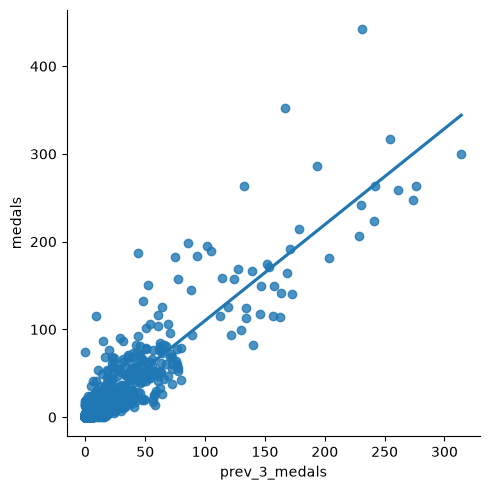

In [32]:
import seaborn as sns

sns.lmplot(x='prev_3_medals', y='medals', data=teams, fit_reg=True, ci=None)

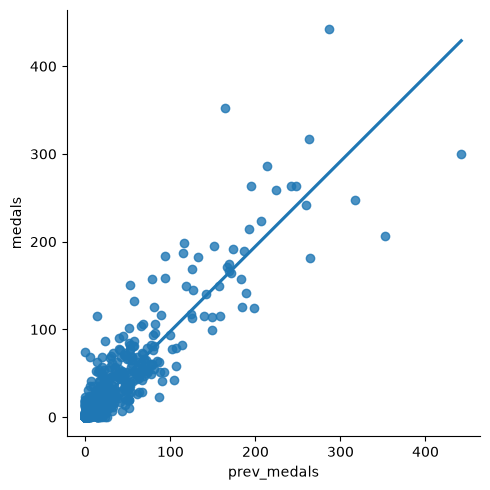

In [33]:
sns.lmplot(x='prev_medals', y='medals', data=teams, fit_reg=True, ci=None)

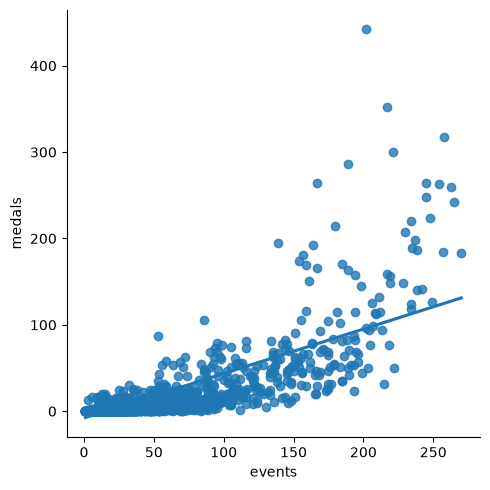

In [34]:
sns.lmplot(x='events', y='medals', data=teams, fit_reg=True, ci=None)

In [35]:
teams[teams.isnull().any(axis=1)] # shows rows with missing values

,team,country,year,events,athletes,age,height,weight,medals,prev_medals,prev_3_medals
19,ALB,Albania,1992,8,9,25.3,163.0,75.2,0,NaN,NaN
26,ALG,Algeria,1964,7,7,26.0,175.0,65.0,0,NaN,NaN
39,AND,Andorra,1976,2,3,28.3,174.7,78.0,0,NaN,NaN
50,ANG,Angola,1980,14,17,17.4,171.7,62.5,0,NaN,NaN
59,ANT,Antigua and Barbuda,1976,11,17,23.2,178.6,71.6,0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
2092,VIN,Saint Vincent and the Grenadines,1988,6,6,20.5,157.0,57.0,0,NaN,NaN
2103,YAR,North Yemen,1984,3,3,27.7,163.3,57.7,0,NaN,NaN
2105,YEM,Yemen,1992,8,8,19.6,169.0,60.0,0,NaN,NaN
2112,YMD,South Yemen,1988,5,5,23.6,175.0,63.3,0,NaN,NaN


In [36]:
teams = teams.dropna() #drop NaN rows
teams

,team,country,year,events,athletes,age,height,weight,medals,prev_medals,prev_3_medals
0,AFG,Afghanistan,1964,8,8,22.0,161.0,64.2,0,0.0,0.0
1,AFG,Afghanistan,1968,5,5,23.2,170.2,70.0,0,0.0,0.0
2,AFG,Afghanistan,1972,8,8,29.0,168.3,63.8,0,0.0,0.0
3,AFG,Afghanistan,1980,11,11,23.6,168.4,63.2,0,0.0,0.0
4,AFG,Afghanistan,2004,5,5,18.6,170.8,64.8,0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...
2139,ZIM,Zimbabwe,2000,19,26,25.0,179.0,71.1,0,0.0,0.0
2140,ZIM,Zimbabwe,2004,11,14,25.1,177.8,70.5,3,0.0,0.0
2141,ZIM,Zimbabwe,2008,15,16,26.1,171.9,63.7,4,3.0,1.0
2142,ZIM,Zimbabwe,2012,8,9,27.3,174.4,65.2,0,4.0,2.3


In [37]:
# split teams into 2 parts, one for training and one for testing
training_data = teams[teams['year'] < 2012].copy()
testing_data = teams[teams['year'] >= 2012].copy()

In [38]:
training_data.shape

(1609, 11)

In [39]:
testing_data.shape

(405, 11)

In [40]:
from sklearn.linear_model import LinearRegression

training_model = LinearRegression()

In [41]:
training_data.corr(numeric_only=True)['medals']

year            -0.033123
events           0.759694
athletes         0.828850
age             -0.000100
height           0.129795
weight           0.087011
medals           1.000000
prev_medals      0.914838
prev_3_medals    0.918729
Name: medals, dtype: float64

In [45]:
features = ['events', 'athletes', 'height', 'prev_medals', 'prev_3_medals']
label = 'medals'

In [ ]:
training_model.fit(training_data[features], training_data[label]) # here we train (fit) with both features and labels from the training data

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](5,)","[-0.39, 0.22, 0.05, 0.37, 0.42]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](5,)","['events','athletes','height','prev_medals','prev_3_medals']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-7.877
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(5)


In [ ]:
model_predictions = training_model.predict(testing_data[features]) # here we ask the model to predict the labels while giving it only the features from the testing data

In [48]:
testing_data['predictions'] = model_predictions

testing_data

,team,country,year,events,athletes,age,height,weight,medals,prev_medals,prev_3_medals,predictions
6,AFG,Afghanistan,2012,6,6,24.8,171.7,60.8,1,1.0,0.3,0.226584
7,AFG,Afghanistan,2016,3,3,24.7,173.7,74.0,0,1.0,0.7,1.005504
24,ALB,Albania,2012,9,10,25.7,176.8,80.2,0,0.0,0.0,-0.304964
25,ALB,Albania,2016,6,6,23.7,176.2,67.2,0,0.0,0.0,-0.042390
37,ALG,Algeria,2012,29,39,24.8,174.3,66.9,1,2.0,2.3,-0.168002
...,...,...,...,...,...,...,...,...,...,...,...,...
2111,YEM,Yemen,2016,3,3,19.3,169.7,65.7,0,0.0,0.0,0.140429
2131,ZAM,Zambia,2012,7,7,22.6,176.2,74.2,0,0.0,0.0,-0.212198
2132,ZAM,Zambia,2016,7,7,24.1,175.2,67.5,0,0.0,0.0,-0.262444
2142,ZIM,Zimbabwe,2012,8,9,27.3,174.4,65.2,0,4.0,2.3,2.189345


In [50]:
testing_data.loc[testing_data['predictions'] < 0, 'predictions'] = 0

testing_data['predictions'] = testing_data['predictions'].round()

testing_data


,team,country,year,events,athletes,age,height,weight,medals,prev_medals,prev_3_medals,predictions
6,AFG,Afghanistan,2012,6,6,24.8,171.7,60.8,1,1.0,0.3,0.0
7,AFG,Afghanistan,2016,3,3,24.7,173.7,74.0,0,1.0,0.7,1.0
24,ALB,Albania,2012,9,10,25.7,176.8,80.2,0,0.0,0.0,0.0
25,ALB,Albania,2016,6,6,23.7,176.2,67.2,0,0.0,0.0,0.0
37,ALG,Algeria,2012,29,39,24.8,174.3,66.9,1,2.0,2.3,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
2111,YEM,Yemen,2016,3,3,19.3,169.7,65.7,0,0.0,0.0,0.0
2131,ZAM,Zambia,2012,7,7,22.6,176.2,74.2,0,0.0,0.0,0.0
2132,ZAM,Zambia,2016,7,7,24.1,175.2,67.5,0,0.0,0.0,0.0
2142,ZIM,Zimbabwe,2012,8,9,27.3,174.4,65.2,0,4.0,2.3,2.0


In [51]:
testing_data = testing_data[['team', 'country', 'year', 'events', 'athletes', 'height', 'age', 'prev_medals', 'prev_3_medals', 'medals', 'predictions']]

testing_data

,team,country,year,events,athletes,height,age,prev_medals,prev_3_medals,medals,predictions
6,AFG,Afghanistan,2012,6,6,171.7,24.8,1.0,0.3,1,0.0
7,AFG,Afghanistan,2016,3,3,173.7,24.7,1.0,0.7,0,1.0
24,ALB,Albania,2012,9,10,176.8,25.7,0.0,0.0,0,0.0
25,ALB,Albania,2016,6,6,176.2,23.7,0.0,0.0,0,0.0
37,ALG,Algeria,2012,29,39,174.3,24.8,2.0,2.3,1,0.0
...,...,...,...,...,...,...,...,...,...,...,...
2111,YEM,Yemen,2016,3,3,169.7,19.3,0.0,0.0,0,0.0
2131,ZAM,Zambia,2012,7,7,176.2,22.6,0.0,0.0,0,0.0
2132,ZAM,Zambia,2016,7,7,175.2,24.1,0.0,0.0,0,0.0
2142,ZIM,Zimbabwe,2012,8,9,174.4,27.3,4.0,2.3,0,2.0


In [ ]:
from sklearn.metrics import mean_absolute_error

MAE = mean_absolute_error(testing_data['medals'], testing_data['predictions'])

MAE

3.4419753086419753

In [54]:
import numpy as np

feature_sets = {
    'athletes, prev_medals': ['athletes', 'prev_medals'],
    'all 5': ['events', 'athletes', 'height', 'prev_medals', 'prev_3_medals'],
    'drop height': ['events', 'athletes', 'prev_medals', 'prev_3_medals'],
    'athletes, prev_medals, prev_3_medals': ['athletes', 'prev_medals', 'prev_3_medals'],
    'events, athletes, prev_medals': ['events', 'athletes', 'prev_medals'],
}

In [55]:
feature_sets

{'athletes, prev_medals': ['athletes', 'prev_medals'],
 'all 5': ['events', 'athletes', 'height', 'prev_medals', 'prev_3_medals'],
 'drop height': ['events', 'athletes', 'prev_medals', 'prev_3_medals'],
 'athletes, prev_medals, prev_3_medals': ['athletes',
  'prev_medals',
  'prev_3_medals'],
 'events, athletes, prev_medals': ['events', 'athletes', 'prev_medals']}

In [ ]:
results = []

for name, cols in feature_sets.items():
    training_model.fit(training_data[cols], training_data[label])

    preds = training_model.predict(testing_data[cols])
    preds = np.clip(preds, 0, None).round()    # same clean-up as before

    mae = mean_absolute_error(testing_data[label], preds)
    results.append({'predictors': name, 'MAE': round(mae, 3)})

pd.DataFrame(results).sort_values('MAE')

,predictors,MAE
4,"events, athletes, prev_medals",3.269
0,"athletes, prev_medals",3.299
2,drop height,3.402
1,all 5,3.442
3,"athletes, prev_medals, prev_3_medals",3.583


THOUGHTS
1. Adding events barely helped ~ it improved MAE marginally by 0.03
2. atheletes, prev_medals still the best features
3. prev_3_medals hurts. It overlaps strongly with prev_medals and so its more noise really. All predictors that included it have higher MAE
4. Height too doesnt help. dropping it improves things
5. More features does not mean better fit/model in this case